In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [5]:
# Load dataset
iris = load_iris(as_frame=True)
df = iris.frame.copy()

In [13]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


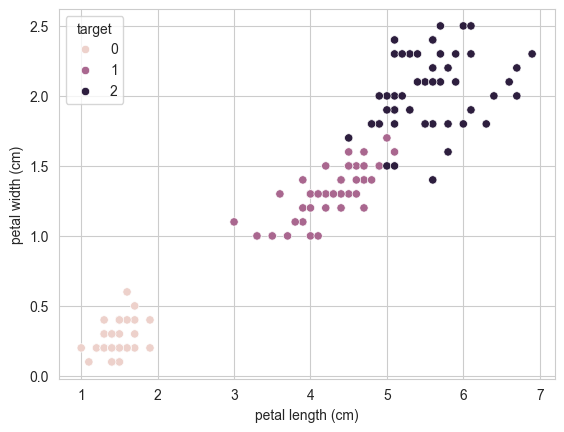

In [15]:
sns.set_style("whitegrid")

# Scatter plot
sns.scatterplot(data=df, x="petal length (cm)",
                y="petal width (cm)",
                hue="target")

plt.show()


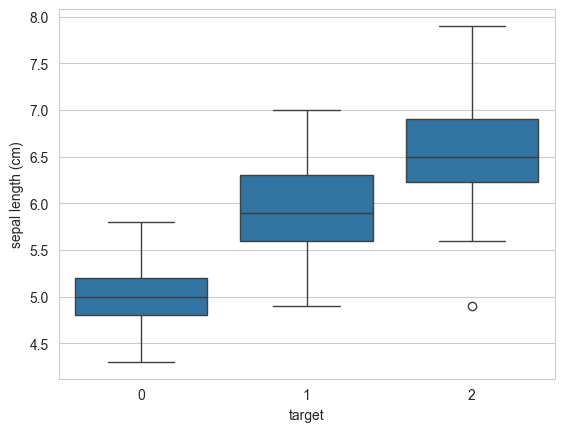

In [16]:
# Box plot
sns.boxplot(data=df, x="target",
            y="sepal length (cm)")


plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (120, 4)
Testing: (30, 4)


In [8]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train_normalized = sc.fit_transform(X_train)
X_test_normalized = sc.transform(X_test)

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB 
from sklearn.svm import LinearSVC
from sklearn.linear_model import Perceptron
knn_classifier = KNeighborsClassifier(n_neighbors=5, weights='uniform', algorithm='auto')
gnb = GaussianNB()
linear_SVM = LinearSVC(penalty='l2', loss='squared_hinge')
perceptron_model = Perceptron(penalty=None, alpha=0.0001) 

In [10]:
# KNN
knn_classifier.fit(X_train_normalized, y_train)
y_pred_knn = knn_classifier.predict(X_test_normalized)

# Gaussian Naive Bayes
gnb.fit(X_train_normalized, y_train)
y_pred_gnb = gnb.predict(X_test_normalized)

# Linear SVM
linear_SVM.fit(X_train_normalized, y_train)
y_pred_svm = linear_SVM.predict(X_test_normalized)

# Perceptron
perceptron_model.fit(X_train_normalized, y_train)
y_pred_perceptron = perceptron_model.predict(X_test_normalized)

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n===== {model_name} =====")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Evaluate all classifiers
evaluate_model(y_test, y_pred_knn, "KNN")
evaluate_model(y_test, y_pred_gnb, "Gaussian Naive Bayes")
evaluate_model(y_test, y_pred_svm, "Linear SVM")
evaluate_model(y_test, y_pred_perceptron, "Perceptron")


===== KNN =====
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.83      1.00      0.91        10
           2       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

===== Gaussian Naive Bayes =====
Accuracy: 0.9667

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 